# BlueMart Retail Analysis
**Steps:** Load → Inspect → Clean → Merge → Answer 8 business questions → Inventory & margin insights

| # | Business question |
|---|---|
| 1 | How are sales changing over time? |
| 2 | Which categories generate the highest sales & profit? |
| 3 | Which products or brands are most profitable? |
| 4 | Which stores and cities are performing best? |
| 5 | Which sales channels contribute the most revenue? |
| 6 | Which high-selling products have low inventory? |
| 7 | Which products are below their reorder point? |
| 8 | Which products have high sales but low profit? |

## Step 1 · Settings and loading the data

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

In [8]:
DATA_FOLDER = "C:/Users/TC/OneDrive/Pictures/Data Analytic/projects/Bluemart_Sales_Analysis/data"
FAST_SELLER_PERCENTILE = 0.80   # items at or above the 80th percentile of daily sales = top 20% = "high-selling"
LOW_STOCK_DAYS = 14            # fewer than 14 days of stock = "low inventory"
RECENT_DAYS = 90               # sales speed is measured over the last 90 days

In [9]:
# ---- Chart colours and look ----
BLUE, RED, AMBER, GREEN = "#2563eb", "#dc2626", "#f59e0b", "#16a34a"
plt.rcParams.update({
    "figure.dpi": 100, "font.size": 10, "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False,
})
pd.options.display.float_format = "{:,.1f}".format

In [10]:
# ---- Load the four files ----
sales     = pd.read_csv(f"{DATA_FOLDER}/bm_sales.csv", parse_dates=["date"])
skus      = pd.read_csv(f"{DATA_FOLDER}/bm_skus.csv")
stores    = pd.read_csv(f"{DATA_FOLDER}/bm_stores.csv", parse_dates=["opening_date"])
inventory = pd.read_csv(f"{DATA_FOLDER}/bm_inventory.csv", parse_dates=["last_restock_date", "snapshot_date"])
for name, table in [("sales", sales), ("skus", skus), ("stores", stores), ("inventory", inventory)]:
    print(f"{name:10s} rows x columns = {table.shape}")
sales.head()

sales      rows x columns = (641843, 9)
skus       rows x columns = (200, 7)
stores     rows x columns = (50, 5)
inventory  rows x columns = (8735, 7)


,date,store_id,sku_id,customer_id,quantity,unit_price,total_value,channel,discount_pct
0,2021-01-01,26,1124,"2,961.0",1,20.1,20.1,Store,15.0
1,2021-01-01,19,1035,NaN,3,208.6,625.7,Store,15.0
2,2021-01-01,38,1088,NaN,1,18.0,18.0,Website,15.0
3,2021-01-01,3,1164,"3,694.0",6,196.2,"1,177.4",Website,0.0
4,2021-01-01,2,1093,"1,252.0",1,8.0,8.0,Store,0.0


### Helper functions (every chart is drawn the same way)

In [11]:
def draw_bars(ax, values, color=BLUE, number_format="{:,.0f}", horizontal=True):
    names = values.index.astype(str)
    if horizontal:
        ax.barh(names, values.values, color=color)
        ax.invert_yaxis()                                   # biggest bar on top
        for position, value in enumerate(values.values):
            ax.text(value, position, " " + number_format.format(value), va="center", fontsize=8)
    else:
        ax.bar(names, values.values, color=color)
        for position, value in enumerate(values.values):
            ax.text(position, value, number_format.format(value), ha="center", va="bottom", fontsize=8)
def percent(part, whole):
    """part as a percentage of whole."""
    return part / whole * 100

## Step 2 · Data Inspection

In [12]:
print("Sales date range:", sales["date"].min().date(), "to", sales["date"].max().date())

Sales date range: 2021-01-01 to 2025-10-31


In [13]:
# to check the number of missing values
print("Missing values in sales:")
print(sales.isna().sum()[lambda counts: counts > 0].to_string())

Missing values in sales:
customer_id    159821


In [14]:
#to count the number of duplicate values
sales.duplicated().sum()

np.int64(45)

In [15]:
print("Sales per channel:")
print(sales["channel"].value_counts().to_string())
sales.describe().T

Sales per channel:
channel
Store        274802
Website      174549
MobileApp    111264
Amazon.ae     55171
Noon          26057


,count,mean,min,25%,50%,75%,max,std
date,641843,2023-05-20 21:46:27.468586,2021-01-01 00:00:00,2022-02-25 00:00:00,2023-05-19 00:00:00,2024-07-31 00:00:00,2025-10-31 00:00:00,NaN
store_id,"641,843.0",25.5,1.0,13.0,25.0,38.0,50.0,14.4
sku_id,"641,843.0","1,100.5","1,001.0","1,051.0","1,101.0","1,150.0","1,200.0",57.7
customer_id,"482,022.0","2,505.0",1.0,"1,260.0","2,507.0","3,752.0","5,000.0","1,442.3"
quantity,"641,843.0",2.6,1.0,1.0,2.0,4.0,6.0,1.5
unit_price,"641,843.0",44.1,1.7,14.3,24.3,49.6,245.4,49.0
total_value,"641,843.0",114.1,1.7,27.3,57.7,129.6,"1,472.3",157.2
discount_pct,"641,843.0",5.4,0.0,0.0,0.0,10.0,35.0,8.7


In [16]:
# These checks should all print 0. A non-zero number would mean a data problem.
print("Sales rows with unknown SKU  :", (~sales["sku_id"].isin(skus["sku_id"])).sum())
print("Sales rows with unknown store:", (~sales["store_id"].isin(stores["store_id"])).sum())
calculated_total = sales["quantity"] * sales["unit_price"]
print("Rows where quantity x price != total_value:", ((calculated_total - sales["total_value"]).abs() > 0.02).sum())
print("SKUs where cost >= selling price:", (skus["cost_price"] >= skus["unit_price"]).sum())
print("Duplicate store/SKU pairs in inventory:", inventory.duplicated(["store_id", "sku_id"]).sum())

Sales rows with unknown SKU  : 0
Sales rows with unknown store: 0
Rows where quantity x price != total_value: 0
SKUs where cost >= selling price: 0
Duplicate store/SKU pairs in inventory: 0


**What we found:** the data is very clean. There are only two things to note:
- 45 exact duplicate sales rows to remove.
- `customer_id` is blank on about 160k rows.These are guest checkouts , So it is normal, so we keep them.

The `unit_price` in the sales table is already **after discount**, so `total_value` is the true revenue.

## Step 3 · Clean

In [17]:
rows_before = len(sales)
rows_before

641843

In [18]:
sales = sales.drop_duplicates().reset_index(drop=True)
print(f"Removed {rows_before - len(sales)} duplicate rows. {len(sales):,} sales rows remain.")


Removed 45 duplicate rows. 641,798 sales rows remain.


In [19]:
sales["customer_id"] = sales["customer_id"].astype("Int64")
sales["customer_id"]

0         2961
1         <NA>
2         <NA>
3         3694
4         1252
          ... 
641793    2525
641794    3091
641795    2345
641796    1945
641797    1411
Name: customer_id, Length: 641798, dtype: Int64

In [20]:
skus = skus.drop_duplicates()
skus

,sku_id,sku_name,category,subcategory,unit_price,cost_price,brand
0,1001,Electronics_Chargers_1001,Electronics,Chargers,164.6,103.4,Budget
1,1002,Dairy_Cream_1002,Dairy,Cream,13.7,9.0,Local
2,1003,Household_Cleaning Supplies_1003,Household,Cleaning Supplies,12.0,7.5,BlueMart
3,1004,Beverages_Juices_1004,Beverages,Juices,24.8,17.6,International
4,1005,Household_Paper Products_1005,Household,Paper Products,17.7,13.7,Budget
...,...,...,...,...,...,...,...
195,1196,Grocery_Pasta_1196,Grocery,Pasta,29.9,21.3,Local
196,1197,Electronics_Mobile Accessories_1197,Electronics,Mobile Accessories,17.6,10.3,International
197,1198,Dairy_Cheese_1198,Dairy,Cheese,25.9,18.1,Budget
198,1199,Electronics_Cables_1199,Electronics,Cables,229.9,150.5,Premium


In [21]:
stores = stores.drop_duplicates()
stores

,store_id,store_name,city,store_type,opening_date
0,9,BlueMart Store 09,Abu Dhabi,Mall,2017-01-01 00:00:00.000000000
1,10,BlueMart Store 10,Abu Dhabi,Mall,2017-01-31 00:00:00.000000000
2,11,BlueMart Store 11,Dubai,Mall,2017-03-02 00:00:00.000000000
3,12,BlueMart Store 12,Sharjah,Mall,2017-04-01 00:00:00.000000000
4,13,BlueMart Store 13,Sharjah,Community,2017-05-01 00:00:00.000000000
5,14,BlueMart Store 14,Dubai,Mall,2017-05-31 00:00:00.000000000
6,15,BlueMart Store 15,Dubai,Mall,2017-06-30 00:00:00.000000000
7,16,BlueMart Store 16,Dubai,High Street,2017-07-30 00:00:00.000000000
8,17,BlueMart Store 17,Dubai,Mall,2017-08-29 00:00:00.000000000
9,18,BlueMart Store 18,Abu Dhabi,Community,2017-09-28 00:00:00.000000000


## Step 4 · Merge into one table and add calculated columns

In [22]:
# In the SKU table `unit_price` is the list price.
skus_renamed = skus.rename(columns={"unit_price": "list_price"})
df = sales.merge(skus_renamed, on="sku_id", how="left")      # add product details
df = df.merge(stores, on="store_id", how="left")             # add store details

df["revenue"] = df["total_value"]                            # already includes the discount
df["cost"]    = df["quantity"] * df["cost_price"]
df["profit"]  = df["revenue"] - df["cost"]
df["year"]    = df["date"].dt.year
df["month"]   = df["date"].dt.to_period("M").dt.to_timestamp()

total_revenue = df["revenue"].sum()
total_profit = df["profit"].sum()
print(f"Merged table: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Revenue {total_revenue:,.0f} | Profit {total_profit:,.0f} | Margin {percent(total_profit, total_revenue):.1f}%")


Merged table: 641,798 rows x 24 columns
Revenue 73,209,783 | Profit 21,097,411 | Margin 28.8%


In [23]:
df.head()

,date,store_id,sku_id,customer_id,quantity,unit_price,total_value,channel,discount_pct,sku_name,...,brand,store_name,city,store_type,opening_date,revenue,cost,profit,year,month
0,2021-01-01,26,1124,2961,1,20.1,20.1,Store,15.0,Dairy_Cheese_1124,...,Premium,BlueMart Store 26,Abu Dhabi,High Street,2017-06-01 08:11:42.439024392,20.1,13.6,6.5,2021,2021-01-01
1,2021-01-01,19,1035,<NA>,3,208.6,625.7,Store,15.0,Electronics_Batteries_1035,...,Premium,BlueMart Store 19,Dubai,Mall,2017-03-31 00:35:07.317073171,625.7,418.7,207.0,2021,2021-01-01
2,2021-01-01,38,1088,<NA>,1,18.0,18.0,Website,15.0,Household_Cleaning Supplies_1088,...,BlueMart,BlueMart Store 38,Dubai,High Street,2017-09-16 04:05:51.219512196,18.0,15.3,2.7,2021,2021-01-01
3,2021-01-01,3,1164,3694,6,196.2,"1,177.4",Website,0.0,Electronics_Cables_1164,...,BlueMart,BlueMart Store 03,Abu Dhabi,Community,2017-07-31 00:00:00.000000000,"1,177.4",757.8,419.6,2021,2021-01-01
4,2021-01-01,2,1093,1252,1,8.0,8.0,Store,0.0,Snacks_Chips_1093,...,BlueMart,BlueMart Store 02,Sharjah,High Street,2017-07-01 00:00:00.000000000,8.0,5.3,2.7,2021,2021-01-01


## Step 5 · Business questions

### Q1. How are sales changing over time?

,revenue,profit,growth_%,JanOct_growth_%
year,,,,
2021,"15,328,941.5","4,463,074.4",NaN,NaN
2022,"14,900,959.2","4,180,832.1",-2.8,-3.6
2023,"14,575,050.3","4,165,264.0",-2.2,-2.1
2024,"15,340,701.2","4,566,250.6",5.3,6.6
2025,"13,064,130.7","3,721,989.5",-14.8,-3.4


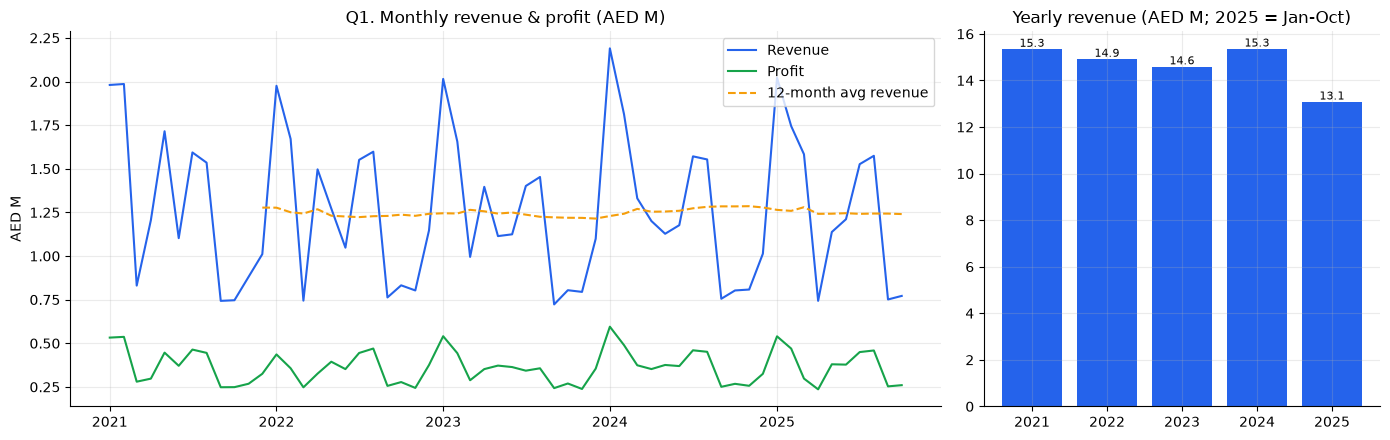

In [24]:
monthly = df.groupby("month")[["revenue", "profit"]].sum()
yearly = df.groupby("year")[["revenue", "profit"]].sum()
yearly["growth_%"] = yearly["revenue"].pct_change()*100

# because 2025 only has Jan-Oct data, so let's compare each year's Jan-Oct for a fair growth number
jan_to_oct_revenue = df[df["date"].dt.month <= 10].groupby("year")["revenue"].sum()
yearly["JanOct_growth_%"] = jan_to_oct_revenue.pct_change() * 100
display(yearly)

fig, (ax_line, ax_bar) = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [2.2, 1]})
ax_line.plot(monthly.index, monthly["revenue"] / 1e6, color=BLUE, label="Revenue")
ax_line.plot(monthly.index, monthly["profit"] / 1e6, color=GREEN, label="Profit")
ax_line.plot(monthly.index, monthly["revenue"].rolling(12).mean() / 1e6, "--", color=AMBER, label="12-month avg revenue")
ax_line.set(title="Q1. Monthly revenue & profit (AED M)", ylabel="AED M")
ax_line.legend()
draw_bars(ax_bar, yearly["revenue"] / 1e6, number_format="{:.1f}", horizontal=False)
ax_bar.set_title("Yearly revenue (AED M; 2025 = Jan-Oct)")
plt.tight_layout(); plt.show()

**Answer:** Sales have barely moved in five years, around AED 15M a year. 2024 was the one good year (+5%). 2025 looks like a drop, but that’s because the data stops at October. Comparing the same Jan–Oct months, 2025 is only about 3% down on 2024.

### Q2. Which categories generate the highest sales & profit?

,revenue,profit,margin_%,revenue_share_%
category,,,,
Electronics,"40,790,950.9","11,848,265.1",29.0,55.7
Household,"8,190,735.9","2,360,418.1",28.8,11.2
Personal Care,"8,181,799.3","2,115,959.3",25.9,11.2
Grocery,"5,564,702.4","1,661,022.6",29.8,7.6
Snacks,"4,321,275.2","1,299,444.1",30.1,5.9
Dairy,"4,238,161.6","1,237,884.7",29.2,5.8
Beverages,"1,922,157.6","574,416.6",29.9,2.6


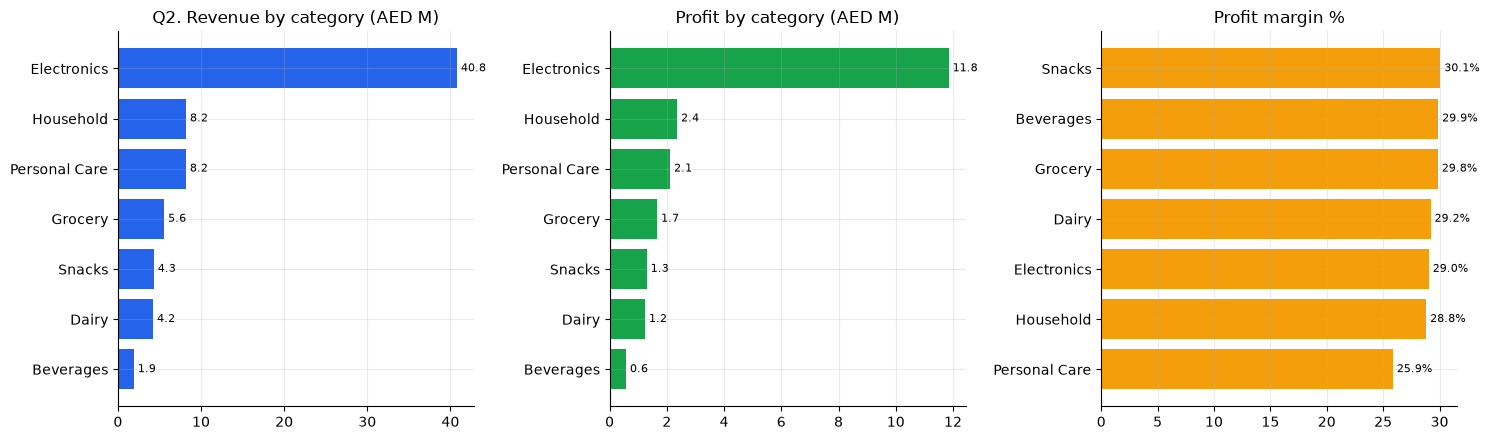

In [25]:
category = df.groupby("category").agg(revenue=("revenue", "sum"), profit=("profit", "sum"))
category["margin_%"] = percent(category["profit"], category["revenue"])
category["revenue_share_%"] = percent(category["revenue"], category["revenue"].sum())
category = category.sort_values("revenue", ascending=False)
display(category)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4.5))
draw_bars(ax1, category["revenue"] / 1e6, number_format="{:.1f}")
ax1.set_title("Q2. Revenue by category (AED M)")
draw_bars(ax2, category["profit"].sort_values(ascending=False) / 1e6, GREEN, "{:.1f}")
ax2.set_title("Profit by category (AED M)")
draw_bars(ax3, category["margin_%"].sort_values(ascending=False), AMBER, "{:.1f}%")
ax3.set_title("Profit margin %")
plt.tight_layout(); plt.show()

**Answer:** Electronics is about 55% of both revenue and profit. Personal Care has the weakest margin (25.9%).

### Q3. Which products or brands are most profitable?

,sku_id,sku_name,category,brand,revenue,profit,units,margin_%
34,1035,Electronics_Batteries_1035,Electronics,Premium,"1,968,289.0","768,459.4",8596,39.0
173,1174,Electronics_Mobile Accessories_1174,Electronics,Premium,"1,851,457.2","689,974.7",8213,37.3
77,1078,Electronics_Cables_1078,Electronics,Local,"1,403,360.7","552,599.0",8331,39.4
198,1199,Electronics_Cables_1199,Electronics,Premium,"1,788,582.3","541,908.0",8283,30.3
172,1173,Electronics_Batteries_1173,Electronics,Budget,"1,252,212.3","511,288.8",8187,40.8
163,1164,Electronics_Cables_1164,Electronics,BlueMart,"1,541,797.1","480,119.3",8406,31.1
64,1065,Electronics_Chargers_1065,Electronics,International,"1,383,637.9","442,198.0",8310,32.0
0,1001,Electronics_Chargers_1001,Electronics,Budget,"1,312,228.4","428,333.6",8545,32.6
158,1159,Electronics_Batteries_1159,Electronics,Premium,"1,419,403.9","378,660.4",8523,26.7
36,1037,Electronics_Cables_1037,Electronics,BlueMart,"1,427,421.1","373,219.6",8525,26.1


,revenue,profit,margin_%
brand,,,
Premium,"24,565,232.7","7,211,636.2",29.4
Budget,"15,236,364.9","4,272,190.7",28.0
BlueMart,"11,281,540.2","3,367,629.4",29.9
Local,"11,710,813.3","3,366,094.2",28.7
International,"10,415,831.9","2,879,860.1",27.6


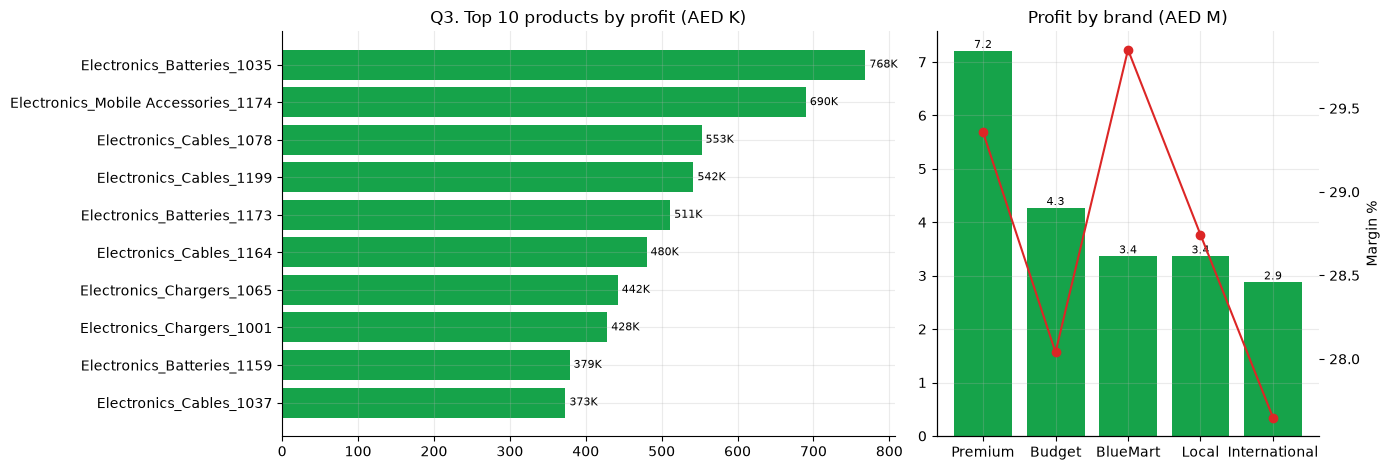

In [26]:
products = df.groupby(["sku_id", "sku_name", "category", "brand"]).agg(
    revenue=("revenue", "sum"), profit=("profit", "sum"), units=("quantity", "sum")
).reset_index()
products["margin_%"] = percent(products["profit"], products["revenue"])

brands = df.groupby("brand").agg(revenue=("revenue", "sum"), profit=("profit", "sum"))
brands["margin_%"] = percent(brands["profit"], brands["revenue"])
brands = brands.sort_values("profit", ascending=False)

top_10_products = products.nlargest(10, "profit")
display(top_10_products)
display(brands)

fig, (ax_products, ax_brands) = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})
draw_bars(ax_products, top_10_products.set_index("sku_name")["profit"] / 1e3, GREEN, "{:.0f}K")
ax_products.set_title("Q3. Top 10 products by profit (AED K)")
draw_bars(ax_brands, brands["profit"] / 1e6, GREEN, "{:.1f}", horizontal=False)
ax_brands.set_title("Profit by brand (AED M)")
ax_margin = ax_brands.twinx()                         # second y-axis for the margin line
ax_margin.plot(brands.index, brands["margin_%"], "o-", color=RED)
ax_margin.set_ylabel("Margin %")
ax_margin.grid(False)
plt.tight_layout(); plt.show()

**Answer:** all of the top 10 products by profit are Electronics (batteries, cables, chargers). Premium is the most profitable brand. Brand margins are close together (27.6% to 29.9%).

### Q4. Which stores and cities are performing best?

,revenue,profit,share_%
city,,,
Dubai,"41,041,586.4","11,827,564.0",56.1
Abu Dhabi,"20,492,594.1","5,911,681.7",28.0
Sharjah,"11,675,602.5","3,358,164.8",15.9


,revenue,stores,revenue_per_store
store_type,,,
Community,"14,600,529.3",10,"1,460,052.9"
High Street,"26,305,740.0",18,"1,461,430.0"
Mall,"32,303,513.7",22,"1,468,341.5"


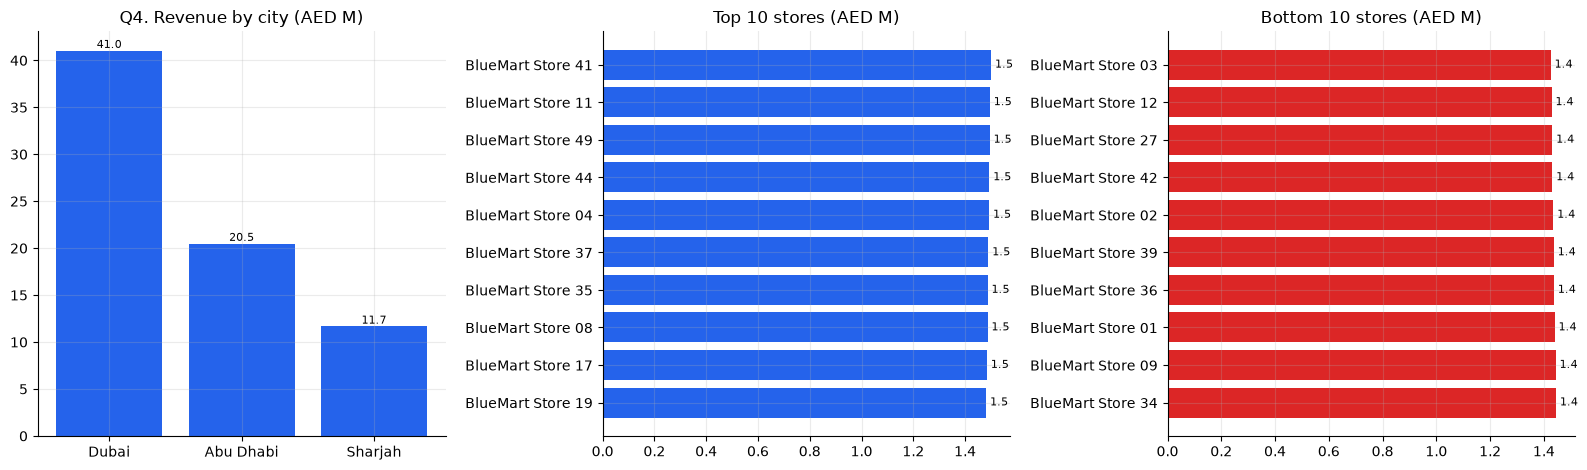

In [27]:
cities = df.groupby("city").agg(revenue=("revenue", "sum"), profit=("profit", "sum"))
cities["share_%"] = percent(cities["revenue"], cities["revenue"].sum())
cities = cities.sort_values("revenue", ascending=False)

store_table = df.groupby(["store_id", "store_name", "city", "store_type"]).agg(
    revenue=("revenue", "sum"), profit=("profit", "sum")
).reset_index()

store_types = df.groupby("store_type").agg(revenue=("revenue", "sum"), stores=("store_id", "nunique"))
store_types["revenue_per_store"] = store_types["revenue"] / store_types["stores"]
display(cities)
display(store_types)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 4.8))
draw_bars(ax1, cities["revenue"] / 1e6, number_format="{:.1f}", horizontal=False)
ax1.set_title("Q4. Revenue by city (AED M)")
draw_bars(ax2, store_table.nlargest(10, "revenue").set_index("store_name")["revenue"] / 1e6, BLUE, "{:.1f}")
ax2.set_title("Top 10 stores (AED M)")
draw_bars(ax3, store_table.nsmallest(10, "revenue").set_index("store_name")["revenue"] / 1e6, RED, "{:.1f}")
ax3.set_title("Bottom 10 stores (AED M)")
plt.tight_layout(); plt.show()

**Answer:** Dubai brings in 56% of revenue. The three store formats (Mall, High Street, Community) earn almost the same per store (about AED 1.46M), so the gaps between stores come mostly from city and store age, not format.

### Q5. Which sales channels contribute the most revenue?

,revenue,profit,avg_line_value,share_%,margin_%
channel,,,,,
Store,"30,227,603.5","8,922,283.9",110.0,41.3,29.5
Website,"20,299,836.6","5,763,231.8",116.3,27.7,28.4
MobileApp,"13,097,435.7","3,704,181.9",117.7,17.9,28.3
Amazon.ae,"6,470,717.9","1,832,503.2",117.3,8.8,28.3
Noon,"3,114,189.2","875,209.7",119.5,4.3,28.1


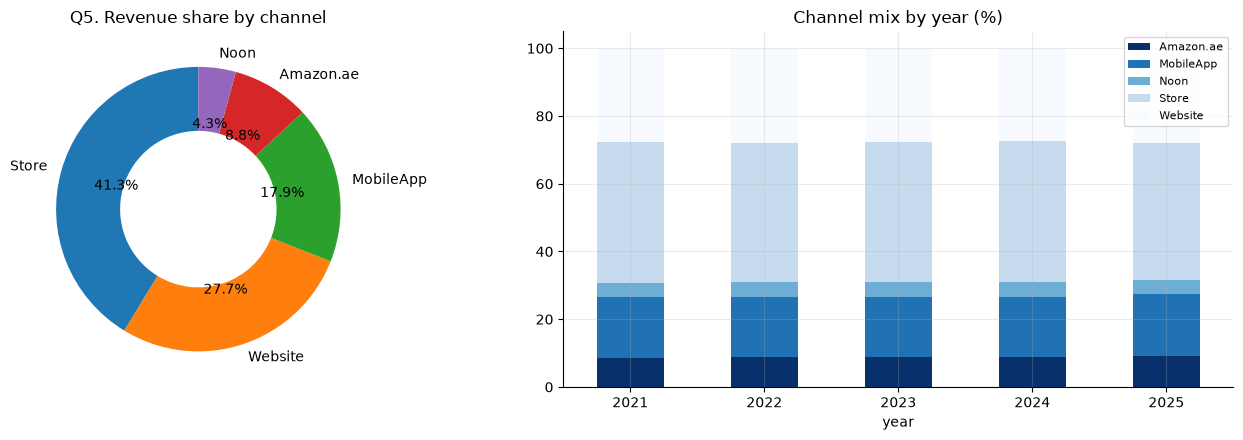

In [ ]:
channels = df.groupby("channel").agg(
    revenue=("revenue", "sum"), profit=("profit", "sum"), avg_line_value=("revenue", "mean")
)
channels["share_%"] = percent(channels["revenue"], channels["revenue"].sum())
channels["margin_%"] = percent(channels["profit"], channels["revenue"])
channels = channels.sort_values("revenue", ascending=False)
display(channels)

# Share of each channel within every year (each row adds up to 100%)
channel_by_year = df.pivot_table(index="year", columns="channel", values="revenue", aggfunc="sum")
channel_by_year = channel_by_year.div(channel_by_year.sum(axis=1), axis=0) * 100

fig, (ax_pie, ax_stack) = plt.subplots(1, 2, figsize=(14, 4.5))
ax_pie.pie(channels["revenue"], labels=channels.index, autopct="%1.1f%%", startangle=90, wedgeprops=dict(width=0.45))
ax_pie.set_title("Q5. Revenue share by channel")
channel_by_year.plot(kind="bar", stacked=True, ax=ax_stack, colormap="Blues_r", rot=0)
ax_stack.set_title("Channel mix by year (%)")
ax_stack.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Answer:** physical stores lead with 41% of revenue, then the Website (28%) and MobileApp (18%). The marketplaces (Amazon.ae and Noon) are small and earn slightly lower margins.

### Inventory preparation (used by Q6 and Q7)
We measure how fast each item sells in each store over the last 90 days, then work out how many **days of stock** are left.

In [29]:
# Units sold per day, per store and item, over the last 90 days
latest_date = df["date"].max()
recent_sales = df[df["date"] > latest_date - pd.Timedelta(days=RECENT_DAYS)]
daily_speed = recent_sales.groupby(["store_id", "sku_id"])["quantity"].sum() / RECENT_DAYS
daily_speed = daily_speed.rename("daily_units").reset_index()

In [30]:
# Join product names,store names and sales speed onto the inventory table
inv = inventory.merge(skus[["sku_id", "sku_name", "category", "brand"]], on="sku_id")
inv = inv.merge(stores[["store_id", "store_name", "city"]], on="store_id")
inv = inv.merge(daily_speed, on=["store_id", "sku_id"], how="left")
inv["daily_units"] = inv["daily_units"].fillna(0)             # no recent sales = 0

In [31]:
# Days of cover = how many days the current stock lasts at the recent sales speed
inv["days_cover"] = np.where(inv["daily_units"] > 0, inv["stock_on_hand"] / inv["daily_units"], np.inf)
inv["stock_to_reorder"] = inv["stock_on_hand"] / inv["reorder_point"]
inv["below_reorder"] = inv["stock_on_hand"] < inv["reorder_point"]
inv["below_safety"] = inv["stock_on_hand"] < inv["safety_stock"]
inv.head()

,store_id,sku_id,stock_on_hand,reorder_point,safety_stock,last_restock_date,snapshot_date,sku_name,category,brand,store_name,city,daily_units,days_cover,stock_to_reorder,below_reorder,below_safety
0,9,1101,300,92,46,2025-10-18,2025-10-31,Snacks_Crackers_1101,Snacks,Local,BlueMart Store 09,Abu Dhabi,0.1,"2,700.0",3.3,False,False
1,9,1021,425,162,81,2025-10-21,2025-10-31,Grocery_Canned Goods_1021,Grocery,BlueMart,BlueMart Store 09,Abu Dhabi,0.0,"9,562.5",2.6,False,False
2,9,1200,252,85,42,2025-09-14,2025-10-31,Beverages_Juices_1200,Beverages,BlueMart,BlueMart Store 09,Abu Dhabi,0.1,"4,536.0",3.0,False,False
3,9,1041,220,87,43,2025-10-13,2025-10-31,Snacks_Nuts_1041,Snacks,Local,BlueMart Store 09,Abu Dhabi,0.1,"2,475.0",2.5,False,False
4,9,1092,170,80,40,2025-09-12,2025-10-31,Household_Detergent_1092,Household,Premium,BlueMart Store 09,Abu Dhabi,0.0,"5,100.0",2.1,False,False


Store-item pairs: 8,735 | with no sales in the last 90 days: 591


,count,mean,std,min,25%,50%,75%,max
stock_on_hand,"8,735.0",170.8,77.9,35.0,112.0,156.0,217.0,449.0
reorder_point,"8,735.0",67.8,33.0,10.0,43.0,62.0,87.0,217.0
safety_stock,"8,735.0",33.6,16.5,5.0,21.0,31.0,43.0,108.0
daily_units,"8,735.0",0.1,0.1,0.0,0.0,0.1,0.1,0.4
days_cover,"8,144.0","3,762.1","4,299.5",166.7,"1,327.5","2,340.0","4,266.0","39,960.0"


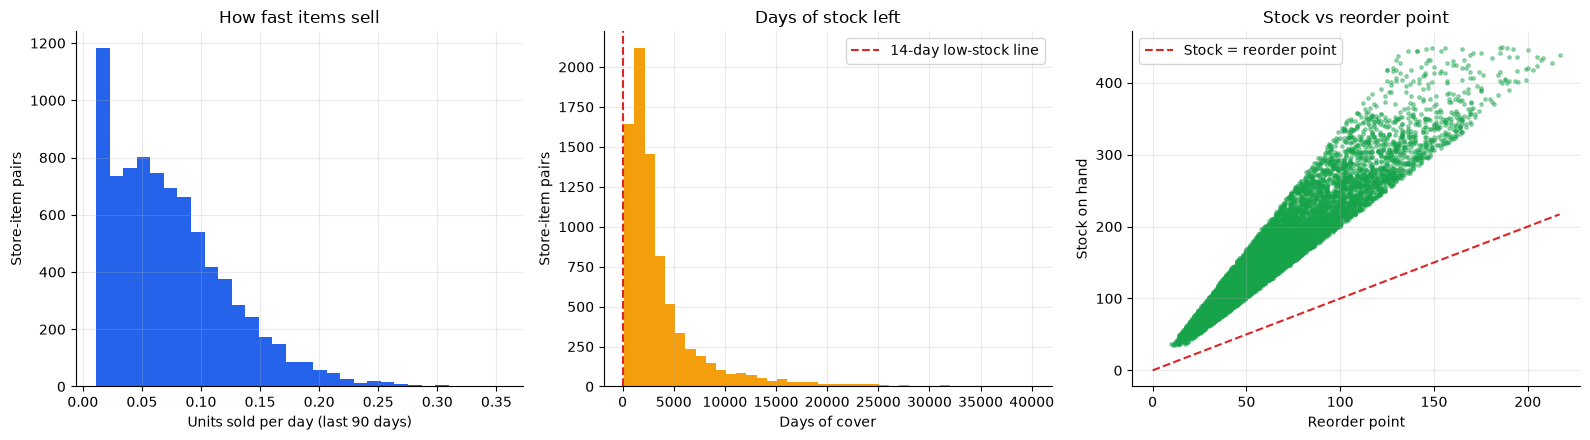

In [32]:
# Summary table of the inventory columns (items with no recent sales have infinite cover, so we leave them out)
cover_ready = inv.replace([np.inf, -np.inf], np.nan)
print(f"Store-item pairs: {len(inv):,} | with no sales in the last {RECENT_DAYS} days: {(inv['daily_units'] == 0).sum():,}")
display(cover_ready[["stock_on_hand", "reorder_point", "safety_stock", "daily_units", "days_cover"]].describe().T)
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 4.5))
ax1.hist(inv.loc[inv["daily_units"] > 0, "daily_units"], bins=30, color=BLUE)
ax1.set(title="How fast items sell", xlabel="Units sold per day (last 90 days)", ylabel="Store-item pairs")
ax2.hist(cover_ready["days_cover"].dropna(), bins=40, color=AMBER)
ax2.axvline(LOW_STOCK_DAYS, color=RED, ls="--", label=f"{LOW_STOCK_DAYS}-day low-stock line")
ax2.set(title="Days of stock left", xlabel="Days of cover", ylabel="Store-item pairs")
ax2.legend()
ax3.scatter(inv["reorder_point"], inv["stock_on_hand"], s=6, alpha=0.4, color=GREEN)
top = inv["reorder_point"].max()
ax3.plot([0, top], [0, top], color=RED, ls="--", label="Stock = reorder point")
ax3.set(title="Stock vs reorder point", xlabel="Reorder point", ylabel="Stock on hand")
ax3.legend()
plt.tight_layout(); plt.show()

### Q6. Which high-selling products have low inventory?

In [33]:
speed_cutoff = inv["daily_units"].quantile(FAST_SELLER_PERCENTILE)
fast_sellers = inv[inv["daily_units"] >= speed_cutoff]
truly_low = (fast_sellers["days_cover"] < LOW_STOCK_DAYS).sum()
print(f"Fast sellers: {len(fast_sellers)} store-item pairs (>= {speed_cutoff:.2f} units/day)")
print(f"Of those, with less than {LOW_STOCK_DAYS} days of stock: {truly_low}")

# Nothing is truly low, so we rank fast sellers by lowest cover as a "watchlist"
watchlist = fast_sellers.sort_values("days_cover")
display(watchlist[["store_name", "sku_name", "stock_on_hand", "reorder_point", "daily_units", "days_cover"]].head(10))

Fast sellers: 2016 store-item pairs (>= 0.11 units/day)
Of those, with less than 14 days of stock: 0


,store_name,sku_name,stock_on_hand,reorder_point,daily_units,days_cover
3076,BlueMart Store 01,Household_Cleaning Supplies_1157,50,21,0.3,166.7
778,BlueMart Store 13,Dairy_Cheese_1083,57,26,0.3,190.0
1633,BlueMart Store 18,Electronics_Cables_1078,36,14,0.2,190.6
4716,BlueMart Store 03,Dairy_Cream_1002,58,20,0.3,200.8
1660,BlueMart Store 18,Electronics_Batteries_1109,40,17,0.2,211.8
8014,BlueMart Store 47,Electronics_Batteries_1109,55,25,0.3,215.2
6999,BlueMart Store 06,Electronics_Batteries_1043,53,22,0.2,216.8
2608,BlueMart Store 24,Personal Care_Shampoo_1011,50,17,0.2,225.0
6104,BlueMart Store 39,Electronics_Cables_1019,43,15,0.2,227.6
6962,BlueMart Store 06,Personal Care_Skincare_1061,56,16,0.2,229.1


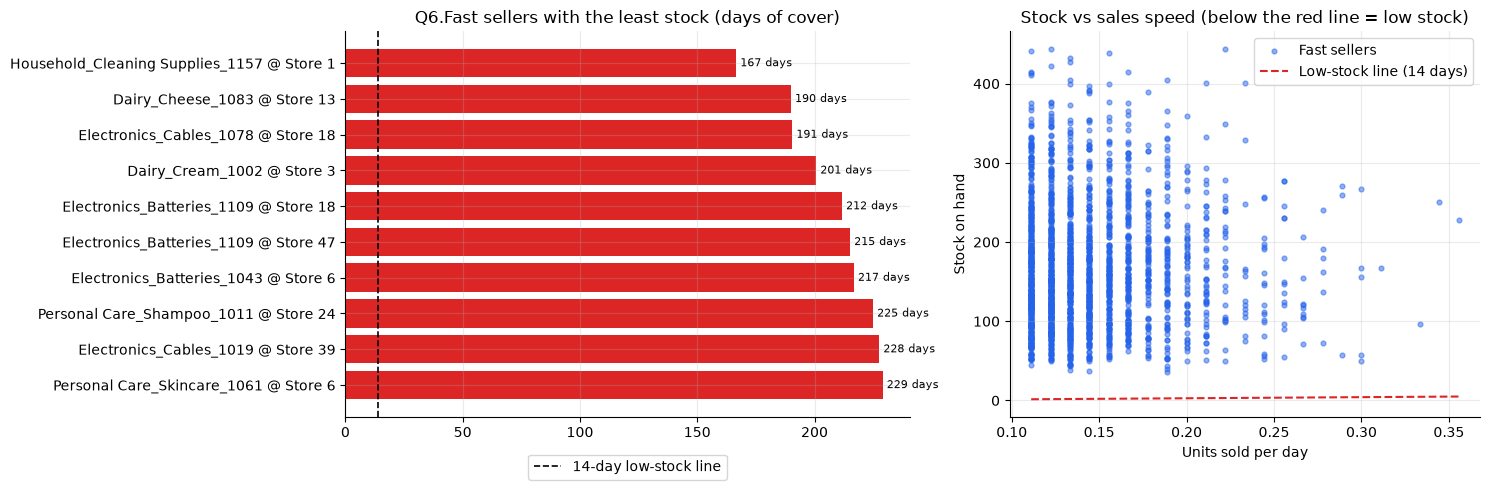

In [34]:
# Left: the 10 fast sellers with the least stock.  Right: every fast seller, stock vs sales speed.
fig, (ax_bar, ax_scatter) = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.2, 1]})

top_watch = watchlist.head(10)
labels = top_watch["sku_name"] + " @ Store " + top_watch["store_id"].astype(str)
draw_bars(ax_bar, pd.Series(top_watch["days_cover"].values, index=labels.values), RED, "{:.0f} days")
ax_bar.axvline(LOW_STOCK_DAYS, color="k", ls="--", lw=1.2, label=f"{LOW_STOCK_DAYS}-day low-stock line")
ax_bar.set_title("Q6.Fast sellers with the least stock (days of cover)")
ax_bar.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08))

ax_scatter.scatter(fast_sellers["daily_units"], fast_sellers["stock_on_hand"], s=12, alpha=0.5, color=BLUE, label="Fast sellers")
x_values = np.linspace(fast_sellers["daily_units"].min(), fast_sellers["daily_units"].max(), 50)
ax_scatter.plot(x_values, x_values * LOW_STOCK_DAYS, color=RED, ls="--", lw=1.5, label=f"Low-stock line ({LOW_STOCK_DAYS} days)")
ax_scatter.set(xlabel="Units sold per day", ylabel="Stock on hand", title="Stock vs sales speed (below the red line = low stock)")
ax_scatter.legend()
plt.tight_layout(); plt.show()

**Answer:** none. Even the fastest sellers have at least about 167 days of stock. The table above is a *relative* watchlist (lowest cover first), not a real shortage list.

### Q7. Which products are below their reorder point?

Below reorder point: 0 of 8,735
Below safety stock : 0
Lowest stock / reorder ratio: 2.00
Median days of cover: 2,340


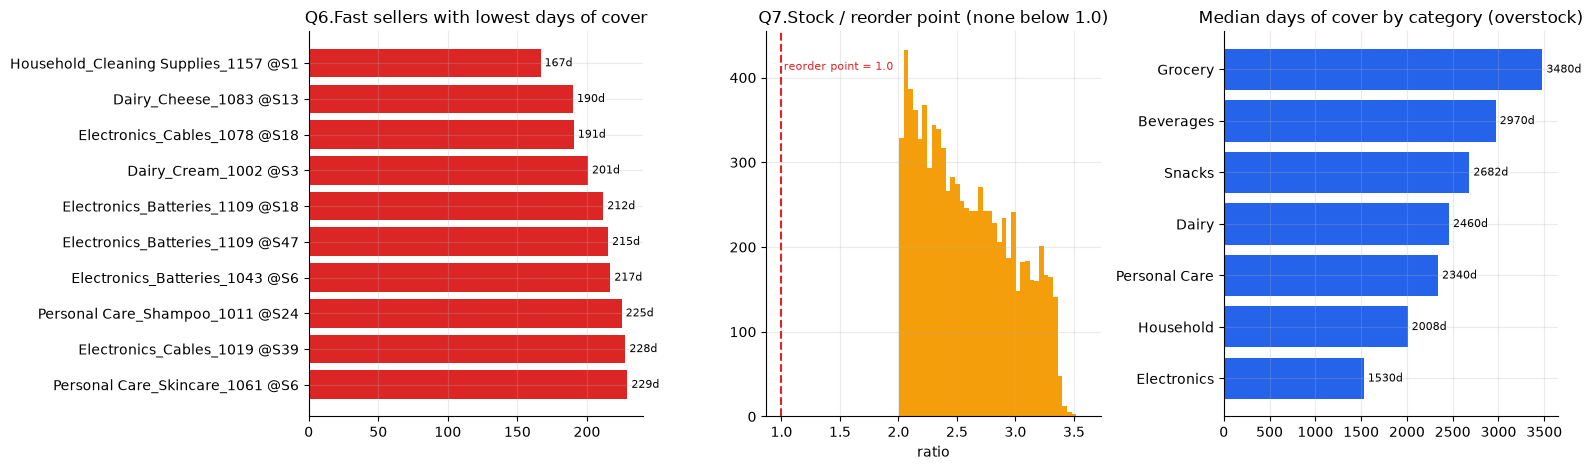

In [35]:
below_reorder = inv[inv["below_reorder"]]
print(f"Below reorder point: {len(below_reorder)} of {len(inv):,}")
print(f"Below safety stock : {inv['below_safety'].sum()}")
print(f"Lowest stock / reorder ratio: {inv['stock_to_reorder'].min():.2f}")

has_sales = inv[inv["days_cover"] != np.inf]
print(f"Median days of cover: {has_sales['days_cover'].median():,.0f}")
cover_by_category = has_sales.groupby("category")["days_cover"].median().sort_values(ascending=False)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 4.8))
top_watch = watchlist.head(10)
watch_labels = top_watch["sku_name"] + " @S" + top_watch["store_id"].astype(str)
draw_bars(ax1, pd.Series(top_watch["days_cover"].values, index=watch_labels.values), RED, "{:.0f}d")
ax1.set_title("Q6.Fast sellers with lowest days of cover")

ax2.hist(inv["stock_to_reorder"], bins=40, color=AMBER)
ax2.axvline(1, color=RED, ls="--")
ax2.text(1.02, ax2.get_ylim()[1] * 0.9, "reorder point = 1.0", color=RED, fontsize=8)
ax2.set(title="Q7.Stock / reorder point (none below 1.0)", xlabel="ratio")

draw_bars(ax3, cover_by_category, BLUE, "{:.0f}d")
ax3.set_title("Median days of cover by category (overstock)")
plt.tight_layout(); plt.show()

**Answer:** none. Every store-item holds at least 2× its reorder point, and stock covers years of current sales. BlueMart's real issue is **overstock**, especially in Grocery and Beverages.
If this looks unrealistic, check that the inventory file is on the same scale as the sales data.

### Q8. Which products have high sales but low profit?

13 products: revenue >= 409,751 and margin <= 23.6%


,sku_name,category,brand,revenue,profit,margin_%
71,Electronics_Chargers_1072,Electronics,Budget,"1,882,741.7","298,431.5",15.9
18,Electronics_Cables_1019,Electronics,Local,"1,592,031.5","366,697.6",23.0
106,Electronics_Mobile Accessories_1107,Electronics,Premium,"1,253,165.3","278,553.3",22.2
150,Electronics_Cables_1151,Electronics,Budget,"1,133,877.6","196,530.0",17.3
171,Electronics_Chargers_1172,Electronics,Premium,"913,077.9","153,088.9",16.8
95,Electronics_Mobile Accessories_1096,Electronics,International,"897,113.0","144,416.4",16.1
97,Electronics_Mobile Accessories_1098,Electronics,Premium,"828,116.7","175,791.4",21.2
67,Electronics_Chargers_1068,Electronics,International,"758,726.8","121,829.3",16.1
184,Personal Care_Toothpaste_1185,Personal Care,BlueMart,"615,214.1","98,621.7",16.0
6,Personal Care_Shampoo_1007,Personal Care,BlueMart,"525,521.1","96,004.0",18.3


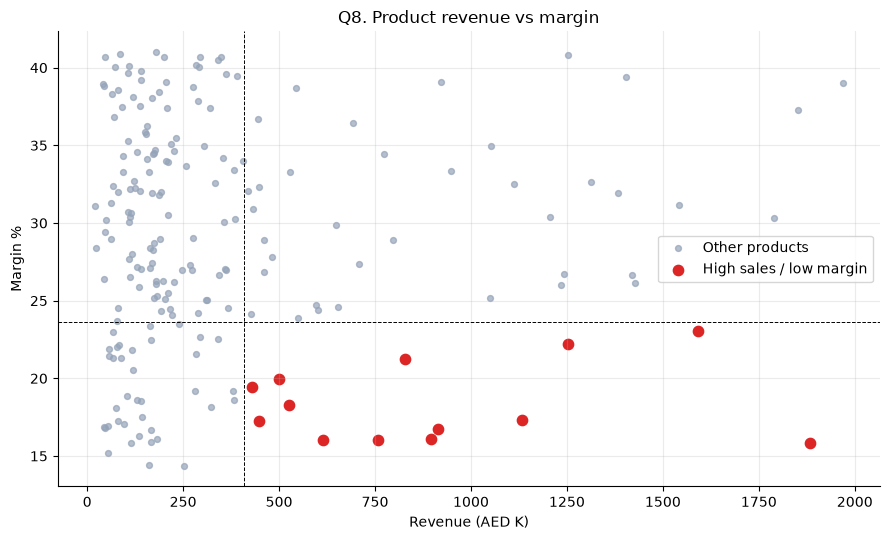

In [36]:
# "High sales" = top 25% by revenue.  "Low profit" = bottom 25% by margin %.
high_revenue_line = products["revenue"].quantile(0.75)
low_margin_line = products["margin_%"].quantile(0.25)
is_problem = (products["revenue"] >= high_revenue_line) & (products["margin_%"] <= low_margin_line)
problem_products = products[is_problem].sort_values("revenue", ascending=False)
print(f"{len(problem_products)} products: revenue >= {high_revenue_line:,.0f} and margin <= {low_margin_line:.1f}%")
display(problem_products[["sku_name", "category", "brand", "revenue", "profit", "margin_%"]])

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(products["revenue"] / 1e3, products["margin_%"], s=18, color="#94a3b8", alpha=0.7, label="Other products")
ax.scatter(problem_products["revenue"] / 1e3, problem_products["margin_%"], s=55, color=RED, label="High sales / low margin")
ax.axvline(high_revenue_line / 1e3, ls="--", c="k", lw=0.7)
ax.axhline(low_margin_line, ls="--", c="k", lw=0.7)
ax.set(xlabel="Revenue (AED K)", ylabel="Margin %", title="Q8. Product revenue vs margin")
ax.legend()
plt.tight_layout(); plt.show()

**Answer:** 13 products, mostly Electronics chargers, cables and accessories, plus some Personal Care items. They sell well but earn only 16–23% margin. They are candidates for repricing, supplier renegotiation, or fewer discounts.

### Do discounts hurt margin?

In [37]:
df["promo"] = df["discount_pct"] > 0
promo = df.groupby("promo").agg(rev=("revenue", "sum"), prof=("profit", "sum"))
promo["margin_%"] = percent(promo["prof"], promo["rev"])
promo

,rev,prof,margin_%
promo,,,
False,"48,303,894.9","16,157,292.6",33.4
True,"24,905,888.1","4,940,118.0",19.8


,rev,prof,margin_%
discount_pct,,,
0.0,"48,303,894.9","16,157,292.6",33.4
10.0,"7,245,253.7","1,890,806.0",26.1
15.0,"9,610,169.4","2,079,749.4",21.6
20.0,"2,739,784.8","460,636.3",16.8
25.0,"4,090,308.7","463,492.2",11.3
30.0,"1,028,826.9","49,792.7",4.8
35.0,"191,544.6","-4,358.6",-2.3


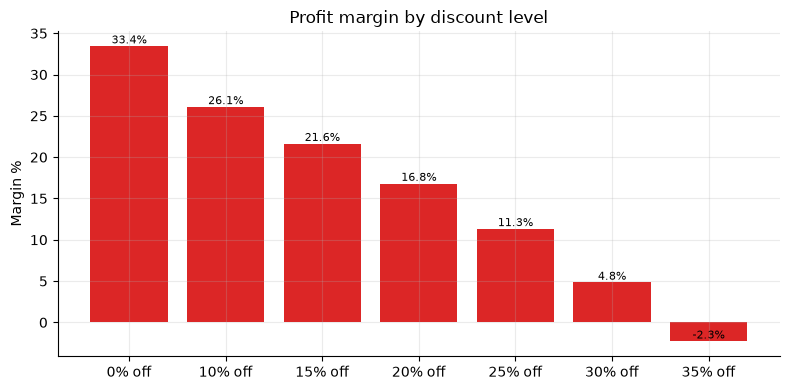

In [38]:
by_discount = df.groupby("discount_pct").agg(rev=("revenue", "sum"), prof=("profit", "sum"))
by_discount["margin_%"] = percent(by_discount["prof"], by_discount["rev"])
display(by_discount)

ax = plt.subplots(figsize=(8, 4))[1]
draw_bars(ax, by_discount["margin_%"].rename(lambda d: f"{d:.0f}% off"), RED, "{:.1f}%", horizontal=False)
ax.set(title="Profit margin by discount level", ylabel="Margin %")
plt.tight_layout(); plt.show()

## Summary of insights
1. **Growth has stalled.** Revenue is about AED 15M a year since 2021; Jan–Oct 2025 is about 3% below 2024.
2. **Concentration risk.** Electronics is about 55% of revenue and profit, and Dubai is 56% of revenue.
3. **Discounts cost margin.** Discounted sales earn about 20% margin vs about 33% at full price.
4. **13 high-volume products have thin margins** (16–23%), mostly Electronics accessories and Personal Care.
5. **Inventory is overstocked, not short.** Nothing is near a reorder trigger. Buying less in Grocery, Beverages and Snacks would free up cash.
6. **Channels.** Physical stores bring in about 41% of revenue; Website and MobileApp together bring about 46%.